In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os, sys, re, random, time
import importlib
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

import data_loaders
import miscellaneous
from rs_algorithm.models import TwoTowerRecommender
from rs_algorithm.models import AdaptiveRepresentation
from dl_trainer import Trainer, split_collate
from data_loaders import CommitedDataset


In [3]:
os.getcwd()

'C:\\Beryllium Base\\WORKSPACES\\MTECH\\RS-project\\sandbox'

In [4]:
data_model = data_loaders.KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [5]:
data_model.ratings.head()

,user_id,item_id,rating,time
0,1520,1357,0.471552,2020-08-19 23:02:14.022
1,4984,8432,0.427609,2020-07-13 16:27:10.746
2,6474,3934,0.851681,2020-07-24 05:24:54.063
3,6435,6264,0.166174,2020-08-18 09:19:47.704
4,1094,8648,0.784189,2020-07-28 18:35:20.47


In [6]:
try:
    ds_train = data_model.get_bpr_dataset()
    smaller_matrix = miscellaneous.keyed_cache("kuairec_smaller_matrix", lambda: data_model.subsample_specimen('small', 10000))
    ds_test = data_model.get_bpr_dataset(smaller_matrix)
except:
    traceback.print_exc()

In [14]:
try:
    n_users, d_user_feats = data_model.user_features.shape
    n_items, d_item_feats = data_model.item_features.shape
    # n_users 7176 d_user_feats 1592
    # n_items 10728 d_item_feats 429

    n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
    n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]
    # n_users 1411 d_user_feats 1592
    # n_items 3327 d_item_feats 429

    uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
    user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=1024, d_embed=1024, id2idx=uid2idx)
    iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
    item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=1024, d_embed=1024, id2idx=iid2idx)
    model = TwoTowerRecommender(user_model, item_model)
except:
    traceback.print_exc()

In [7]:
def loss_fn_all(preds, truth):
    s_pos, s_neg = truth
    r_pos, r_neg = preds

    # is it really necessary?
    r_pos = torch.log1p(r_pos)
    r_neg = torch.log1p(r_neg)

    # regression
    reg_loss = F.mse_loss(s_pos, r_pos) + F.mse_loss(s_neg, r_neg)

    # ranking
    delta = s_pos - s_neg
    rank_loss = -torch.log(torch.sigmoid(delta).type(torch.float32))

    # weight by preference strength
    weight = torch.log1p(torch.clamp(r_pos - r_neg, min=0))
    rank_loss = (rank_loss * weight).mean()

    return reg_loss + rank_loss


def loss_fn_al_v2(preds, truth, lambda_reg=1.0, lambda_rank=1.0):
    s_pos, s_neg = preds
    r_pos, r_neg = truth

    r_pos_t = torch.log1p(r_pos)
    r_neg_t = torch.log1p(r_neg)

    reg_loss = F.mse_loss(s_pos, r_pos_t) + F.mse_loss(s_neg, r_neg_t)

    diff = s_pos - s_neg
    rank_loss = F.softplus(-diff)  # = log(1 + exp(-(s_pos - s_neg)))

    with torch.no_grad():
        weight = torch.log1p(torch.clamp(r_pos - r_neg, min=0))

    rank_loss = (rank_loss * weight).mean()

    loss = lambda_reg * reg_loss + lambda_rank * rank_loss

    return loss


def loss_fn_ranking_only(preds, truth):
    s_pos, s_neg = truth
    r_pos, r_neg = preds
    r_pos = torch.log1p(r_pos)
    r_neg = torch.log1p(r_neg)
    delta = s_pos - s_neg
    rank_loss = -torch.log(torch.sigmoid(delta).type(torch.float32))
    weight = torch.log1p(torch.clamp(r_pos - r_neg, min=0))
    rank_loss = (rank_loss * weight).mean()
    return rank_loss


def loss_fn_mse_only(preds, truth, median=torch.log1p(torch.tensor(0.75))):
    p_pos, p_neg, _ = preds

    t_pos, t_neg = truth
    t_pos = torch.log1p(t_pos) - median
    t_neg = torch.log1p(t_neg) - median

    return F.mse_loss(p_pos, t_pos) + F.mse_loss(p_neg, t_neg)


def loss_fn_cls(preds, truth):
    # Why does it CAUSES NaNs everywhere
    # IMPL NOTE: That was because the dot product can be negative!!! The log was only for normalizing the truth!
    r_pos, r_neg, _ = preds
    # IMPL NOTE: Removed the "-0.75" because it's better to train the model about a boundary of <0&>0
    s_pos, s_neg = torch.ones_like(r_pos), torch.zeros_like(r_neg)
    r_pos, r_neg = torch.sigmoid(r_pos), torch.sigmoid(r_neg)
    cls_loss = F.binary_cross_entropy(r_pos, s_pos) + F.binary_cross_entropy(r_neg, s_neg)
    return cls_loss


def loss_fn_cls_mse(preds, truth):
    r_pos, r_neg, _ = preds
    s_pos, s_neg = torch.ones_like(r_pos), torch.zeros_like(r_neg)
    # IMPL NOTE: Removed the "-0.75" because it's better to train the model about a boundary of <0&>0
    r_pos, r_neg = torch.sigmoid(r_pos), torch.sigmoid(r_neg)
    cls_loss = F.mse_loss(s_pos, r_pos) + F.mse_loss(s_neg, r_neg)
    return cls_loss


def l2_reg(*tensors):
    return sum((t ** 2).mean() for t in tensors)


def id_embed_regularizer(preds, lbd=1):
    _, _, (uie, piie, niie) = preds
    return lbd * l2_reg(uie, piie, niie)


def running_average(arr, window=20):
    return np.convolve(arr, np.ones(window), 'valid') / window

In [8]:
try:
    print(loss_fn_mse_only(
        (torch.tensor([-1.0]), torch.tensor([+1.0]), None),
        (torch.tensor([1.5]), torch.tensor([0.0]))
    ))
    print(loss_fn_mse_only(
        (torch.tensor([+1.0]), torch.tensor([-1.0]), None),
        (torch.tensor([1.5]), torch.tensor([0.0]))
    ))
except:
    traceback.print_exc()

tensor(4.2730)
tensor(0.6078)


In [9]:
try:
    ds_train_v2 = CommitedDataset('KuaiRecData_smaller', os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [11]:
try:
    pol, nel = [], []
    d = np.log1p(.75)
    for _, (_, (p, n)) in zip(tqdm(range(len(ds_train_v2))), ds_train_v2):
        pol.append(p), nel.append(n)
    pol, nel = np.asarray(pol), np.asarray(nel)
    print(np.sum(pol), np.sum(nel))
    print(np.mean(pol), np.mean(nel))
    pol, nel = np.log1p(pol) - d, np.log1p(nel) - d
    print(np.sum(pol), np.sum(nel))
    print(np.mean(pol), np.mean(nel))
except:
    traceback.print_exc()

100%|██████████| 998100/998100 [00:05<00:00, 193003.28it/s]


1.3119294e+06 437383.94
1.3144268 0.43821654
247680.41485884815 -208301.6448710215
0.24815190347545152 -0.20869817139667518


In [29]:
try:
    pol, nel = [], []
    d = np.log1p(.75)
    for _, ((uid, uft, pid, pif, nid, nif), _) in zip(tqdm(range(10000)), ds_train_v2):  # len(ds_train_v2)
        uid, uft, pid, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pid], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))
        with torch.no_grad():
            ue, ub = user_model(uid, uft)
            pie, pib = item_model(pid, pif)
            nie, nib = item_model(nid, nif)
        pos = (ue * pie).sum() + ub + pib
        neg = (ue * nie).sum() + ub + nib
        pol.append(pos.numpy()), nel.append(neg.numpy())
    pol, nel = np.asarray(pol), np.asarray(nel)
    print(np.sum(pol), np.sum(nel))
    print(np.mean(pol), np.mean(nel))
except:
    traceback.print_exc()

100%|██████████| 10000/10000 [00:13<00:00, 768.49it/s]

1455.2849 -416.73257
0.1455285 -0.041673258


## Training the model with focus only on feature based embeddings

Basically asking it to learn the task as closely as possible using only the user and item features

In [15]:
try:
    pre_training_loss = locals().get('pre_training_loss', None)
    pre_trainer = Trainer(
        model=model,
        train_dataloader=DataLoader(ds_train_v2, batch_size=8192),
        # val_dataloader=DataLoader(ds_test, batch_size=1024),
        criterion=loss_fn_mse_only,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.0003),
        epochs=10,
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        loss=pre_training_loss,
    )
    pre_training_loss = pre_trainer.loss
except:
    traceback.print_exc()

In [74]:
try:
    pre_trainer.epochs = 1
    pre_trainer.learning_rate(0.0003)
except:
    traceback.print_exc()

Epoch:  0/ 1    Train Loss: 0.21    TTS: 1.13    ETA: 137.25
Epoch:  0/ 1    Train Loss: 0.21    TTS: 2.27    ETA: 136.50
Epoch:  0/ 1    Train Loss: 0.20    TTS: 3.45    ETA: 136.97
Epoch:  0/ 1    Train Loss: 0.21    TTS: 4.59    ETA: 135.41
Epoch:  0/ 1    Train Loss: 0.21    TTS: 5.67    ETA: 132.67
Epoch:  0/ 1    Train Loss: 0.21    TTS: 6.82    ETA: 131.85
Epoch:  0/ 1    Train Loss: 0.21    TTS: 8.07    ETA: 132.57
Epoch:  0/ 1    Train Loss: 0.21    TTS: 9.16    ETA: 130.47
Epoch:  0/ 1    Train Loss: 0.21    TTS: 10.27    ETA: 128.99
Epoch:  0/ 1    Train Loss: 0.21    TTS: 11.37    ETA: 127.36
Epoch:  0/ 1    Train Loss: 0.21    TTS: 12.55    ETA: 126.68
Epoch:  0/ 1    Train Loss: 0.21    TTS: 13.70    ETA: 125.59
Epoch:  0/ 1    Train Loss: 0.21    TTS: 14.83    ETA: 124.35
Epoch:  0/ 1    Train Loss: 0.21    TTS: 15.91    ETA: 122.75
Epoch:  0/ 1    Train Loss: 0.21    TTS: 17.04    ETA: 121.53
Epoch:  0/ 1    Train Loss: 0.21    TTS: 18.20    ETA: 120.58
Epoch:  0/ 1    

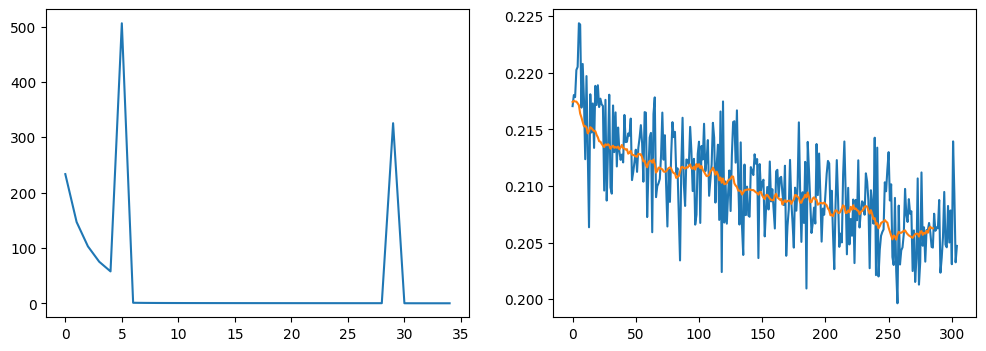

In [78]:
try:
    model.prepare_for_feature_based_embeds_training()
    pre_trainer.train()

    _, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(pre_trainer.loss['train'])
    axs[1].plot(pre_trainer.loss['batch.train'])
    axs[1].plot(running_average(pre_trainer.loss['batch.train'], 20))
except:
    traceback.print_exc()

In [77]:
try:
    print(len(pre_trainer.loss['batch.train']))
    # pre_trainer.loss['batch.train'] = pre_trainer.loss['batch.train'][2800:]
except:
    traceback.print_exc()

2983


In [79]:
try:
    pre_trainer.save_model("pretrained_feature_embedder_v1")
except:
    traceback.print_exc()

## Training the model with focus only on item based embeddings

Allowing it to learn the the item based embeddings (and bias) to close the gap

In [81]:
try:
    id_training_loss = locals().get('id_training_loss', None)
    id_trainer = Trainer(
        model=model,
        train_dataloader=DataLoader(ds_train_v2, batch_size=8192),
        # val_dataloader=DataLoader(ds_test, batch_size=1024),
        criterion=loss_fn_mse_only,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.0003),
        epochs=10,
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        loss=id_training_loss,
    )
    id_training_loss = id_trainer.loss
    id_trainer.load_model("model_id_trained_embedder_v1.pt")
except:
    traceback.print_exc()

In [103]:
try:
    id_trainer.epochs = 1
    id_trainer.learning_rate(0.0003)
except:
    traceback.print_exc()

Epoch:  0/ 1    Train Loss: 0.24    TTS: 1.79    ETA: 107.51
Epoch:  0/ 1    Train Loss: 0.22    TTS: 2.72    ETA: 107.81
Epoch:  0/ 1    Train Loss: 0.23    TTS: 3.70    ETA: 109.01
Epoch:  0/ 1    Train Loss: 0.23    TTS: 4.71    ETA: 110.30
Epoch:  0/ 1    Train Loss: 0.23    TTS: 5.69    ETA: 110.04
Epoch:  0/ 1    Train Loss: 0.23    TTS: 6.70    ETA: 110.03
Epoch:  0/ 1    Train Loss: 0.23    TTS: 7.72    ETA: 110.00
Epoch:  0/ 1    Train Loss: 0.23    TTS: 8.84    ETA: 111.04
Epoch:  0/ 1    Train Loss: 0.23    TTS: 9.83    ETA: 110.07
Epoch:  0/ 1    Train Loss: 0.23    TTS: 10.84    ETA: 109.37
Epoch:  0/ 1    Train Loss: 0.23    TTS: 11.84    ETA: 108.57
Epoch:  0/ 1    Train Loss: 0.23    TTS: 12.97    ETA: 108.72
Epoch:  0/ 1    Train Loss: 0.23    TTS: 13.99    ETA: 107.91
Epoch:  0/ 1    Train Loss: 0.22    TTS: 15.02    ETA: 107.13
Epoch:  0/ 1    Train Loss: 0.23    TTS: 16.04    ETA: 106.27
Epoch:  0/ 1    Train Loss: 0.23    TTS: 17.08    ETA: 105.46
Epoch:  0/ 1    T

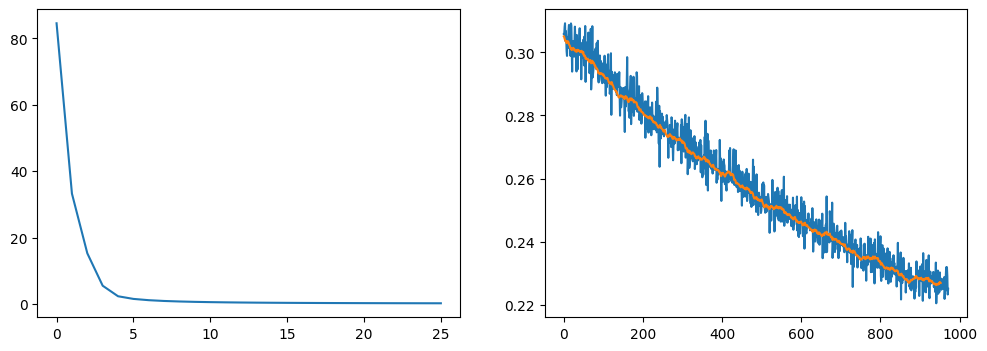

In [105]:
try:
    model.prepare_for_id_based_embeds_training()
    id_trainer.train()

    _, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(id_trainer.loss['train'])
    axs[1].plot(id_trainer.loss['batch.train'])
    axs[1].plot(running_average(id_trainer.loss['batch.train'], 20))
except:
    traceback.print_exc()

In [106]:
try:
    # id_trainer.loss['batch.train'] = id_trainer.loss['batch.train'][1200:]
    print(len(id_trainer.loss['batch.train']))
except:
    traceback.print_exc()

972


In [107]:
try:
    id_trainer.save_model("id_trained_embedder_v1")
except:
    traceback.print_exc()

## Hmmm...

In [307]:
try:
    with torch.no_grad():
        model.eval()
        (uid, uft, pid, pif, nid, nif), (pr, nr) = ds_train_v2[1]
        uid, uft, pid, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pid], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))
        uem, ubs = user_model(uid, uft, use_bias=True)
        pie, pib = item_model(pid, pif, use_bias=True)
        nie, nib = item_model(nid, nif, use_bias=True)
        print("User ID", uid)
        print("Pos  ID", pid)
        print("Neg  ID", nid)
        print("Feat Only Dot Pos", (uem * pie).sum(dim=1))
        print("Feat Only Dot Neg", (uem * nie).sum(dim=1))
        print("With ID   Dot Pos", (uem * pie).sum(dim=1) + ubs + pib)
        print("With ID   Dot Neg", (uem * nie).sum(dim=1) + ubs + nib)
        pos, neg, *_ = model(uid, uft, pid, pif, nid, nif)
        print("Model Output  Pos", pos)
        print("Model Output  Neg", neg)
        print("Ground Truth  Pos", pr - np.log1p(0.75))
        print("Ground Truth  Neg", nr - np.log1p(0.75))
    # TODO: MAKE A COPY OF THIS NOTEBOOK FOR FURTHER EXPERIMENTS, BECAUSE I THINK IT"S PRETTY BEAUTIFUL CURRENTLY
    # TODO: Find out why model outputs are different than what I just calculated manually
    # TODO: Find out why dot product with features only is giving opposite results
except:
    traceback.print_exc()

User ID tensor([2909])
Pos  ID tensor([4667])
Neg  ID tensor([319])
Feat Only Dot Pos tensor([-0.3741])
Feat Only Dot Neg tensor([0.0438])
With ID   Dot Pos tensor([-0.0760])
With ID   Dot Neg tensor([0.0126])
Model Output  Pos tensor([-0.0760])
Model Output  Neg tensor([0.0126])
Ground Truth  Pos 0.490378203916384
Ground Truth  Neg -0.04352748103158355


In [12]:
loss = None

In [12]:
try:
    trainer = Trainer(
        model=model,
        train_dataloader=DataLoader(ds_train_v2, batch_size=8192),
        # train_dataloader=DataLoader(ds_train, batch_size=8192),
        # val_dataloader=DataLoader(ds_test, batch_size=1024),
        # criterion=loss_fn_cls,
        # criterion=loss_fn_cls_mse,
        criterion=loss_fn_mse_only,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.0003),
        regularization=id_embed_regularizer,
        epochs=10,
        # dataset_fraction=10,
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        loss=loss,
    )
    loss = trainer.loss

except:
    traceback.print_exc()

In [13]:
# try:
#     # trainer.load_checkpoint('checkpoint_RegressionBasedBPEModel_001_20260402_171557_0.7496953347667319.pt', save_backup=False)
#     trainer.load_checkpoint('model_embedder_v4.1_mse_only.pt', save_backup=False)
#     # trainer.load_checkpoint(save_backup=False)
# except:
#     traceback.print_exc()

In [14]:
try:
    # trainer.regularization = id_embed_regularizer
    trainer.learning_rate(0.0001)
    trainer.epochs = 1
except:
    traceback.print_exc()

In [55]:
try:
    print(trainer.regularization((None, None, (np.asarray(1), np.asarray(1), np.asarray(1)))))
except:
    traceback.print_exc()

3.0


In [26]:
try:
    trainer.train()
    # ds_train    14m on charger, same on battery
    # ds_train_v2  2m on battery
except:
    traceback.print_exc()

Epoch:  0/ 1    Train Loss: 0.11    Regularization: 0.17    TTS: 1.82    ETA: 220.10
Epoch:  0/ 1    Train Loss: 0.11    Regularization: 0.17    TTS: 3.36    ETA: 201.70
Epoch:  0/ 1    Train Loss: 0.10    Regularization: 0.17    TTS: 4.62    ETA: 183.41
Epoch:  0/ 1    Train Loss: 0.11    Regularization: 0.17    TTS: 5.86    ETA: 172.88
Epoch:  0/ 1    Train Loss: 0.11    Regularization: 0.17    TTS: 7.11    ETA: 166.46
Epoch:  0/ 1    Train Loss: 0.11    Regularization: 0.17    TTS: 8.35    ETA: 161.49
Epoch:  0/ 1    Train Loss: 0.11    Regularization: 0.17    TTS: 9.64    ETA: 158.31
Epoch:  0/ 1    Train Loss: 0.11    Regularization: 0.17    TTS: 10.86    ETA: 154.72
Epoch:  0/ 1    Train Loss: 0.11    Regularization: 0.17    TTS: 12.10    ETA: 151.91
Epoch:  0/ 1    Train Loss: 0.11    Regularization: 0.17    TTS: 13.33    ETA: 149.26
Epoch:  0/ 1    Train Loss: 0.11    Regularization: 0.17    TTS: 14.65    ETA: 147.85
Epoch:  0/ 1    Train Loss: 0.11    Regularization: 0.17    T

dict_keys(['train', 'val', 'epoch.train', 'batch.train'])
4


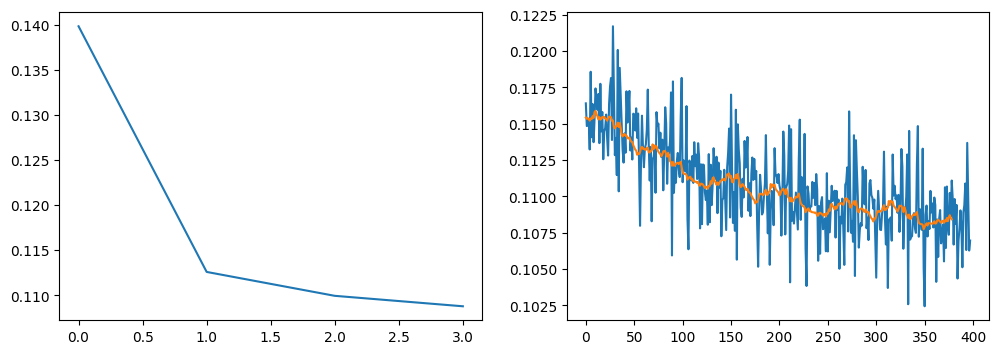

In [27]:
try:
    def running_average(arr, window=20):
        return np.convolve(arr, np.ones(window), 'valid') / window


    print(trainer.loss.keys())
    print(len(trainer.loss['epoch.train']))
    _, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(trainer.loss['train'])
    axs[1].plot(trainer.loss['batch.train'])
    axs[1].plot(running_average(trainer.loss['batch.train']))
except:
    traceback.print_exc()

In [19]:
try:
    print(len(trainer.loss['batch.train']))
    # trainer.loss['total.batch.train'] = trainer.loss['batch.train']
    # trainer.loss['batch.train'] = trainer.loss['batch.train'][80:]
except:
    traceback.print_exc()

112


In [29]:
try:
    trainer.save_model("embedder_v4.1_mse_only")
    trainer.save_loss("embedder_v4.1_mse_only")
except:
    traceback.print_exc()

In [30]:
try:
    with torch.no_grad():
        allfeats = data_model.user_features.iloc[data_model.ratings['user_id'].unique()].to_numpy(dtype=np.float32)
        allfeats = torch.tensor(allfeats, dtype=torch.float32)
        alpha = user_model.alpha(allfeats)
        print("Alpha", alpha.min(), alpha.max(), alpha.mean(), alpha.std())
        uems = (1 - alpha) * user_model.adaptor(allfeats)
        extrema = uems.norm(dim=1)
        print("Feature Based Embeddings")
        print(extrema.min(), extrema.max(), extrema.mean(), extrema.std())

        allids = torch.tensor(list(uid2idx.values()))
        uems = alpha * user_model.embedder(allids)
        extrema = uems.norm(dim=1)
        print("ID Based Embeddings")
        print(extrema.min(), extrema.max(), extrema.mean(), extrema.std())

    # Ideally, id based embeddings should have lesser magnitudes
except:
    traceback.print_exc()

Alpha tensor(0.1894) tensor(0.4071) tensor(0.2372) tensor(0.0307)
Feature Based Embeddings
tensor(15.4731) tensor(21.2617) tensor(19.9563) tensor(0.8185)
ID Based Embeddings
tensor(2.3049) tensor(5.1417) tensor(2.9697) tensor(0.3932)


In [30]:
try:
    timers = trainer.timer.timers
    for key in timers.keys():
        print(f"{key:30s}", timers[key].average)
except:
    traceback.print_exc()

train                          167.36833127500176
_train_step                    167.32111217499914
train_dataloader               0.32867153155747797
batch                          1.0424806844265444


In [ ]:
# train                          889.8823580947372
# _train_step                    889.8518185105257
# train_dataloader               6.364767394226624
# batch                          0.9279501650150535

In [48]:
try:
    with torch.no_grad():
        model.eval()
        (uid, uft, pid, pif, nid, nif), (pr, nr) = next(iter(ds_train))
        uid, uft, pid, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pid], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))
        sample = model(uid, uft, pid, pif, nid, nif)
except:
    traceback.print_exc()

In [49]:
try:
    with torch.no_grad():
        print(sample)
        print(pr, nr)
        print(np.log1p(pr) - np.log1p(0.75), np.log1p(nr) - np.log1p(0.75))

        ue, ub = user_model(uid, uft)
        pie, pib = item_model(pid, pif)
        nie, nib = item_model(nid, nif)
        print((ue * pie).sum())
        print((ue * nie).sum())
        print((ue * pie).sum() + ub + pib)
        print((ue * nie).sum() + ub + nib)
except:
    traceback.print_exc()

(tensor([0.0121]), tensor([-0.1437]), (tensor([[0.4038]]), tensor([[0.3121]]), tensor([[0.3091]])))
0.7787611 0.6773604
0.016301277208162546 -0.04239439673440337
tensor(1.5890)
tensor(0.4299)
tensor([0.0121])
tensor([-0.1437])


In [51]:
try:
    with torch.no_grad():
        pf, pb = item_model(pid, pif)
        nf, nb = item_model(nid, nif)
        print(pf)
        print(nf)
        print(pf + pb)
        print(nf + nb)
except:
    traceback.print_exc()

tensor([[ 0.2183, -0.0158, -0.2572,  ..., -1.4353,  0.1316, -0.0211]])
tensor([[ 2.4066e-01, -2.2058e-02, -2.5821e-01,  ..., -1.4424e+00,
          1.0594e-01, -1.1080e-03]])
tensor([[ 0.3610,  0.1269, -0.1144,  ..., -1.2926,  0.2744,  0.1216]])
tensor([[ 1.3866,  1.1239,  0.8878,  ..., -0.2965,  1.2519,  1.1449]])


In [52]:
try:
    with torch.no_grad():
        print(((pf) * (nf)).sum(dim=1))
        print(((pf + pb) * (nf + nb)).sum(dim=1))
except:
    traceback.print_exc()

tensor([316.5683])
tensor([489.2087])


In [53]:
try:
    r = data_model.ratings
    # print(r['user_id'].unique())
    print(r[(r['user_id'] == 2246)].sort_values('rating'))
    # 9178 739
except:
    traceback.print_exc()

        user_id  item_id    rating                     time
176853     2246     8804  0.000000  2020-08-04 00:02:53.945
633503     2246      867  0.000000  2020-08-03 23:02:40.888
441860     2246     2611  0.003231  2020-08-08 11:35:21.442
973690     2246     4364  0.004699  2020-08-09 05:36:08.837
82854      2246     9824  0.014148                      NaN
...         ...      ...       ...                      ...
668401     2246     2354  1.872266   2020-07-18 18:39:44.35
273780     2246     9907  1.912010  2020-07-23 05:52:44.662
174172     2246     3950  2.107771   2020-07-18 05:26:25.82
119878     2246     6985  3.040702  2020-07-13 11:07:49.141
105908     2246     2343  5.141892   2020-07-18 18:28:52.98

[708 rows x 4 columns]


In [54]:
try:
    with torch.no_grad():
        ui = 2246
        uf = data_model.user_features.iloc[ui].to_numpy(dtype=np.float32)
        aii = 2354
        aif = data_model.item_features.iloc[aii].to_numpy(dtype=np.float32)
        bii = 9907
        bif = data_model.item_features.iloc[bii].to_numpy(dtype=np.float32)
        cii = 2611
        cif = data_model.item_features.iloc[cii].to_numpy(dtype=np.float32)
        ue, ub, uei, ua = user_model(torch.tensor([ui], dtype=torch.long), torch.tensor(uf[None, :], dtype=torch.float), return_id_embeds=True, return_alpha=True)
        ae, ab, aei, aa = item_model(torch.tensor([aii], dtype=torch.long), torch.tensor(aif[None, :], dtype=torch.float), return_id_embeds=True, return_alpha=True)
        be, bb, bei, ba = item_model(torch.tensor([bii], dtype=torch.long), torch.tensor(bif[None, :], dtype=torch.float), return_id_embeds=True, return_alpha=True)
        ce, cb, cei, ca = item_model(torch.tensor([cii], dtype=torch.long), torch.tensor(cif[None, :], dtype=torch.float), return_id_embeds=True, return_alpha=True)
        print("ae * be", (ae * be).sum(dim=1))
        print("ae * ce", (ae * ce).sum(dim=1))
        print("ue * ae", (ue * ae + ub + ab).sum(dim=1))
        print("ue * be", (ue * be + ub + bb).sum(dim=1))
        print("ue * ce", (ue * ce + ub + cb).sum(dim=1))
        print("ua", ua)
        print("||ue|| ", (ue ** 2).sum() ** 0.5)
        print("||uei||", (uei ** 2).sum() ** 0.5)
        print("||uef||", ((ue - uei) ** 2).sum() ** 0.5)
        # print(ae, be)
except:
    traceback.print_exc()

ae * be tensor([322.6534])
ae * ce tensor([343.3974])
ue * ae tensor([1236.1654])
ue * be tensor([528.4728])
ue * ce tensor([1653.3381])
ua tensor([[0.4004]])
||ue||  tensor(16.2855)
||uei|| tensor(5.1177)
||uef|| tensor(16.1656)


In [148]:
try:
    print(np.log1p(0.0) - np.log1p(0.75))
    print(np.log1p(1.5) - np.log1p(0.75))
except:
    traceback.print_exc()

-0.5596157879354227
0.35667494393873245


In [113]:
try:
    with torch.no_grad():
        ui = 2246
        uf = data_model.user_features.iloc[ui].to_numpy(dtype=np.float32)
        aii = 2354
        aif = data_model.item_features.iloc[aii].to_numpy(dtype=np.float32)
        bii = 2343
        bif = data_model.item_features.iloc[bii].to_numpy(dtype=np.float32)
        cii = 2611
        cif = data_model.item_features.iloc[cii].to_numpy(dtype=np.float32)
        ue, ub = user_model(torch.tensor([ui], dtype=torch.long), torch.tensor(uf[None, :], dtype=torch.float))
        ae, ab = item_model(None, torch.tensor(aif[None, :], dtype=torch.float))
        be, bb = item_model(None, torch.tensor(bif[None, :], dtype=torch.float))
        ce, cb = item_model(None, torch.tensor(cif[None, :], dtype=torch.float))
        print((ae * be).sum(dim=1))
        print((ae * ce).sum(dim=1))
        print((ue * ae).sum(dim=1))
        print((ue * ce).sum(dim=1))
        # print(ae, be)
except:
    traceback.print_exc()

tensor([630.9227])
tensor([495.7508])
tensor([89.0869])
tensor([-44.3784])


In [73]:
try:
    with torch.no_grad():
        ae, ab = item_model(torch.tensor([aii], dtype=torch.long), torch.tensor(aif[None, :], dtype=torch.float))
        print((ae ** 2).sum())
        ae, ab = item_model(None, torch.tensor(aif[None, :], dtype=torch.float))
        print((ae ** 2).sum())
except:
    traceback.print_exc()

tensor(525.7579)
tensor(1013.2061)


In [115]:
try:
    with torch.no_grad():
        ui = 2246
        uf = data_model.user_features.iloc[ui].to_numpy(dtype=np.float32)
        aii = 10677
        aif = data_model.item_features.iloc[aii].to_numpy(dtype=np.float32)
        bii = 10693
        bif = data_model.item_features.iloc[bii].to_numpy(dtype=np.float32)
        cii = 2611
        cif = data_model.item_features.iloc[cii].to_numpy(dtype=np.float32)
        ue, ub = user_model(torch.tensor([ui], dtype=torch.long), torch.tensor(uf[None, :], dtype=torch.float))
        ae, ab = item_model(None, torch.tensor(aif[None, :], dtype=torch.float))
        be, bb = item_model(None, torch.tensor(bif[None, :], dtype=torch.float))
        ce, cb = item_model(None, torch.tensor(cif[None, :], dtype=torch.float))
        print((ae * be).sum(dim=1))
        print((ae * ce).sum(dim=1))
        print((ue * ae).sum(dim=1))
        print((ue * ce).sum(dim=1))
        # print(ae, be)
except:
    traceback.print_exc()

tensor([1011.7667])
tensor([588.9796])
tensor([-23.0292])
tensor([-44.3784])


In [114]:
try:
    i = data_model.item_features
    # print(i[(i['first_level_category_name_其他']==1)&(i['second_level_category_name_休闲舞蹈']==1)].shape)
    print(i[(i['first_level_category_name_其他'] == 1) & (i['second_level_category_name_生活泛拍'] == 1)])
except:
    traceback.print_exc()

       first_level_category_name_UNKNOWN  first_level_category_name_三农  \
14                                 False                         False   
22                                 False                         False   
27                                 False                         False   
44                                 False                         False   
59                                 False                         False   
...                                  ...                           ...   
10677                              False                         False   
10693                              False                         False   
10696                              False                         False   
10702                              False                         False   
10710                              False                         False   

       first_level_category_name_二次元  first_level_category_name_亲子  \
14                             False     

In [49]:
i[(i['first_level_category_name_其他'] == 1)]

,first_level_category_name_UNKNOWN,first_level_category_name_三农,first_level_category_name_二次元,first_level_category_name_亲子,first_level_category_name_人文,first_level_category_name_健康,first_level_category_name_健身,first_level_category_name_其他,first_level_category_name_军事,first_level_category_name_喜剧,...,feat_21,feat_22,feat_23,feat_24,feat_25,feat_26,feat_27,feat_28,feat_29,feat_30
14,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
22,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
24,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
27,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
44,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10693,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
10696,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
10702,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
10705,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
